In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob

df = pd.read_parquet('../data/processed/climate_mensal.parquet')

In [14]:
df.head()

precipitacao_mm  radiacao_kj_m2  \
datetime   nome_estacao                                    
2010-01-31 ACARAU                   42.0      816.437736   
           BARBALHA                221.0      848.321698   
           CAMPOS SALES             63.6      763.976383   
           CRATEUS                  84.6      747.555121   
           FORTALEZA                53.4     1038.030795   

                         temperatura_bulbo_seco_c  temperatura_maxima_c  \
datetime   nome_estacao                                                   
2010-01-31 ACARAU                       27.112399             27.690431   
           BARBALHA                     25.261456             25.898652   
           CAMPOS SALES                 24.870175             25.508367   
           CRATEUS                      27.418598             28.031402   
           FORTALEZA                    28.276792             28.774619   

                         temperatura_minima_c  \
datetime   nome_estacao                         
2010-01-31 ACARAU                   26.581671   
           BARBALHA                 24.659164   
           CAMPOS SALES             24.277733   
           CRATEUS                  26.850404   
           FORTALEZA                27.795601   

                         umidade_relativa_maxima_percent  \
datetime   nome_estacao                                    
2010-01-31 ACARAU                              78.985175   
           BARBALHA                            79.551213   
           CAMPOS SALES                        73.392713   
           CRATEUS                             67.340970   
           FORTALEZA                           73.385787   

                         umidade_relativa_minima_percent  \
datetime   nome_estacao                                    
2010-01-31 ACARAU                              74.142857   
           BARBALHA                            72.115903   
           CAMPOS SALES                        67.442645   
           CRATEUS                             61.761456   
           FORTALEZA                           66.901861   

                         umidade_relativa_percent  vento_velocidade_m_s  
datetime   nome_estacao                                                  
2010-01-31 ACARAU                       76.613208              3.244340  
           BARBALHA                     75.897574              1.259704  
           CAMPOS SALES                 70.417004              2.185560  
           CRATEUS                      64.521563              1.959299  
           FORTALEZA                    70.446701              2.751438

In [15]:
df.tail()

precipitacao_mm  radiacao_kj_m2  \
datetime   nome_estacao                                    
2024-12-31 QUIXADA                   6.2     1683.006818   
           QUIXERAMOBIM              4.4     1524.505714   
           SOBRAL                    0.0             NaN   
           TAUA                      0.0             NaN   
           TIANGUA                   0.0             NaN   

                         temperatura_bulbo_seco_c  temperatura_maxima_c  \
datetime   nome_estacao                                                   
2024-12-31 QUIXADA                      31.029825             32.247368   
           QUIXERAMOBIM                 31.032381             31.845952   
           SOBRAL                             NaN                   NaN   
           TAUA                               NaN                   NaN   
           TIANGUA                            NaN                   NaN   

                         temperatura_minima_c  \
datetime   nome_estacao                         
2024-12-31 QUIXADA                  30.295881   
           QUIXERAMOBIM             30.114048   
           SOBRAL                         NaN   
           TAUA                           NaN   
           TIANGUA                        NaN   

                         umidade_relativa_maxima_percent  \
datetime   nome_estacao                                    
2024-12-31 QUIXADA                             66.912234   
           QUIXERAMOBIM                        51.078571   
           SOBRAL                                    NaN   
           TAUA                                      NaN   
           TIANGUA                                   NaN   

                         umidade_relativa_minima_percent  \
datetime   nome_estacao                                    
2024-12-31 QUIXADA                             56.960106   
           QUIXERAMOBIM                        44.426190   
           SOBRAL                                    NaN   
           TAUA                                      NaN   
           TIANGUA                                   NaN   

                         umidade_relativa_percent  vento_velocidade_m_s  
datetime   nome_estacao                                                  
2024-12-31 QUIXADA                      62.798969              3.010200  
           QUIXERAMOBIM                 47.223810              3.690952  
           SOBRAL                             NaN                   NaN  
           TAUA                               NaN                   NaN  
           TIANGUA                            NaN                   NaN

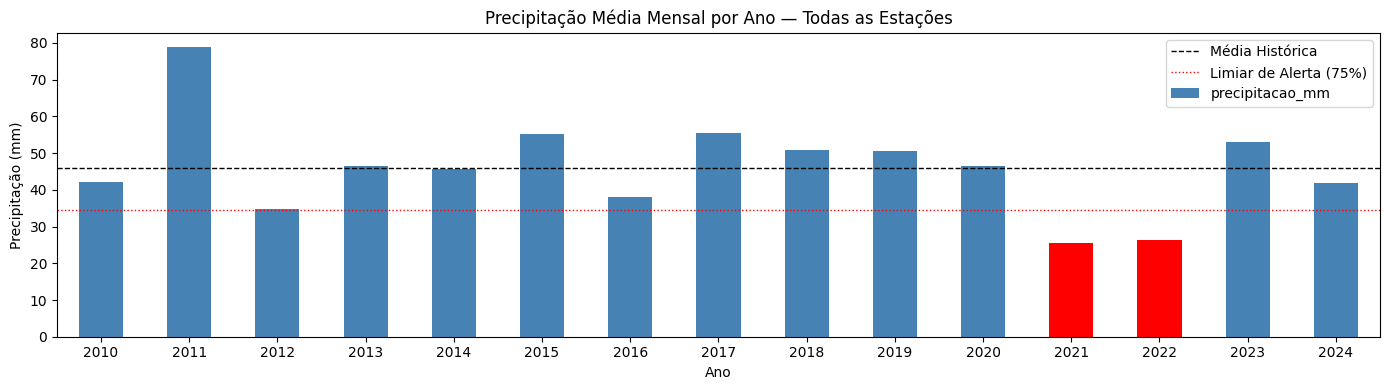

In [16]:
precipitacao = df.loc[(slice(None), slice(None)), 'precipitacao_mm']
precipitacao.index = precipitacao.index.get_level_values('datetime')

precipitacao_media_anual = precipitacao.resample('YE').mean()
precipitacao_media_anual.index = precipitacao_media_anual.index.year

media_historica = precipitacao_media_anual.mean()
threshold = media_historica * 0.75

# Lógica de cores: vermelho para anos abaixo do limiar, azul para os demais
cores = ['red' if v < threshold else 'steelblue' for v in precipitacao_media_anual.values]

# Configuração e plotagem do gráfico
fig, ax = plt.subplots(figsize=(14, 4))
precipitacao_media_anual.plot(kind='bar', color=cores, ax=ax)

# Ajustes visuais (títulos e eixos)
ax.set_title('Precipitação Média Mensal por Ano — Todas as Estações')
ax.set_ylabel('Precipitação (mm)')
ax.set_xlabel('Ano')
ax.tick_params(axis='x', rotation=0)

# Linhas de referência
ax.axhline(y=media_historica, color='black', linestyle='--', linewidth=1, label='Média Histórica')
ax.axhline(y=threshold, color='red', linestyle=':', linewidth=1, label='Limiar de Alerta (75%)')

ax.legend()
plt.tight_layout()
plt.show()

A dinâmica da seca no Ceará é complexa e exige uma perspectiva de longo prazo. Devido à forte sazonalidade da região — onde as chuvas se concentram em uma "quadra chuvosa" em vez de se distribuírem uniformemente ao longo dos meses —, a análise do comportamento histórico é fundamental para identificar anomalias.

Para ilustrar esse cenário, o gráfico abaixo apresenta a média mensal de precipitação agregada por ano. Como métrica de alerta, estabelecemos um limiar crítico (destacado em vermelho) para os anos em que o volume ficou abaixo de 75% da média histórica. Nota-se que o ano de 2012 situou-se exatamente no limiar de atenção, enquanto 2021 e 2022 registraram baixas pluviométricas severas.

In [17]:
sazonalidade = df['precipitacao_mm'].groupby(
    df.index.get_level_values('datetime').month
).mean()

print(sazonalidade)

datetime
1      70.836036
2      92.011712
3     127.683036
4     110.608036
5      53.518750
6      26.347321
7      17.914286
8       3.547321
9       2.059821
10      7.402679
11     12.737500
12     25.916964
Name: precipitacao_mm, dtype: float64


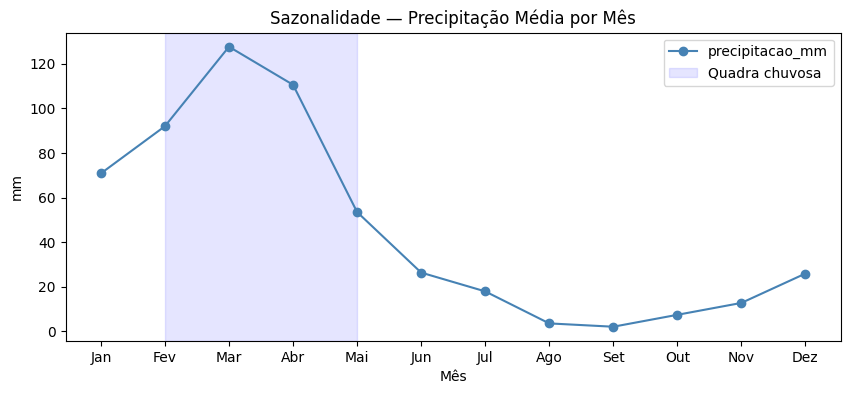

In [18]:
fig, ax = plt.subplots(figsize=(10, 4))
sazonalidade.plot(ax=ax, marker='o', color='steelblue')
ax.set_title('Sazonalidade — Precipitação Média por Mês')
ax.set_ylabel('mm')
ax.set_xlabel('Mês')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Jan','Fev','Mar','Abr','Mai','Jun',
                     'Jul','Ago','Set','Out','Nov','Dez'])
ax.axvspan(2, 5, alpha=0.1, color='blue', label='Quadra chuvosa')
ax.legend()
plt.show()

In [19]:
mascara = df.index.get_level_values('datetime').year.isin([2012, 2016, 2021, 2022])
df_seca = df[mascara]
print(df_seca.shape)

(720, 9)


In [20]:
mascara_normal = ~mascara
df_normal = df[mascara_normal]

In [21]:
temp_seca = df_seca['temperatura_bulbo_seco_c'].mean()
temp_normal = df_normal['temperatura_bulbo_seco_c'].mean()

print(f"Temperatura média anos de seca: {temp_seca:.2f}°C")
print(f"Temperatura média anos normais: {temp_normal:.2f}°C")

Temperatura média anos de seca: 27.39°C
Temperatura média anos normais: 27.03°C


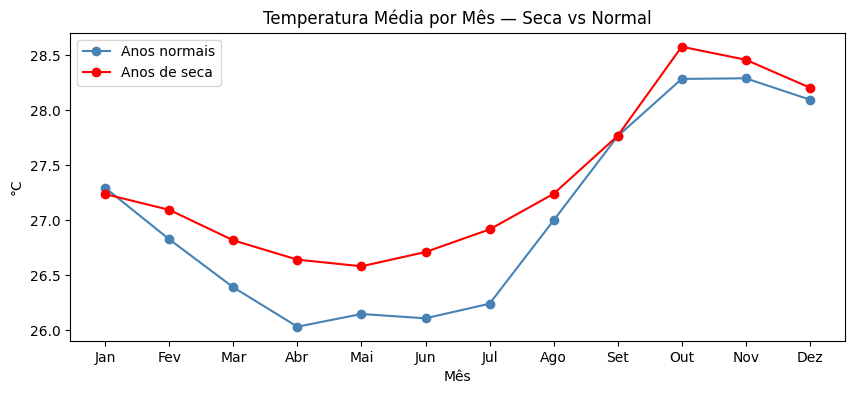

In [22]:
temp_seca_mensal = df_seca['temperatura_bulbo_seco_c'].groupby(
    df_seca.index.get_level_values('datetime').month
).mean()

temp_normal_mensal = df_normal['temperatura_bulbo_seco_c'].groupby(
    df_normal.index.get_level_values('datetime').month
).mean()

fig, ax = plt.subplots(figsize=(10, 4))
temp_normal_mensal.plot(ax=ax, marker='o', label='Anos normais', color='steelblue')
temp_seca_mensal.plot(ax=ax, marker='o', label='Anos de seca', color='red')

ax.set_title('Temperatura Média por Mês — Seca vs Normal')
ax.set_ylabel('°C')
ax.set_xlabel('Mês')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Jan','Fev','Mar','Abr','Mai','Jun',
                     'Jul','Ago','Set','Out','Nov','Dez'])
ax.legend()
plt.show()

In [23]:
diferenca = temp_seca_mensal - temp_normal_mensal
print(diferenca)

datetime
1    -0.057003
2     0.267749
3     0.426926
4     0.609437
5     0.433395
6     0.602021
7     0.674747
8     0.241456
9     0.003603
10    0.292479
11    0.168334
12    0.109308
Name: temperatura_bulbo_seco_c, dtype: float64


In [25]:
df_estacoes = pd.read_parquet('../data/processed/estacoes.parquet')
print(df_estacoes.head())

           nome codigo       lat        lon  altitude
0   MORADA NOVA   A332 -5.091111 -38.364722     93.00
1          TAUA   A324 -6.017500 -40.281389    410.87
2     ITAPIPOCA   A359 -3.484167 -39.588611    104.49
3  GUARAMIRANGA   A314 -4.229167 -38.958889    865.53
4     JAGUARIBE   A358 -5.905556 -38.627778    149.31


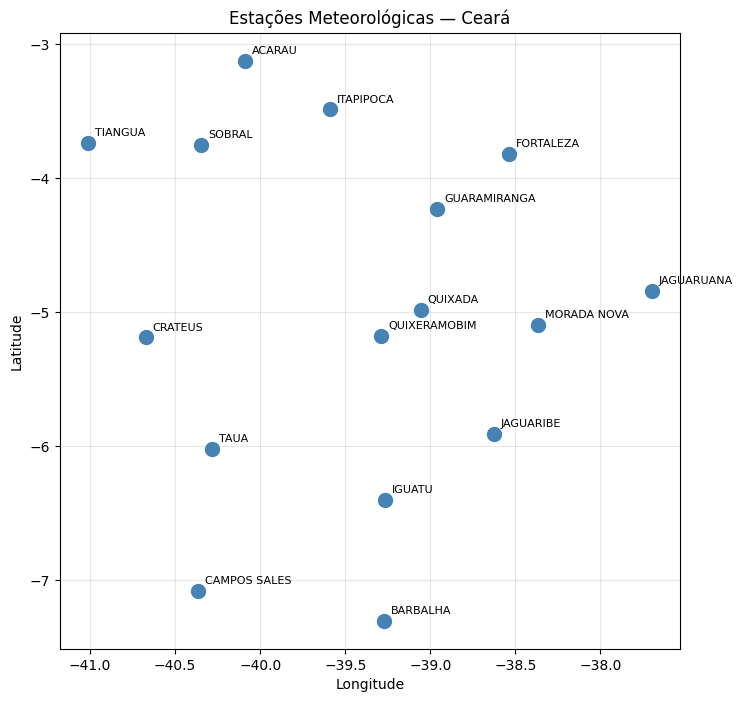

In [ ]:
df_estacoes = pd.read_parquet('../data/processed/estacoes.parquet')

fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(df_estacoes['lon'], df_estacoes['lat'],
           color='steelblue', s=100, zorder=5)

for _, row in df_estacoes.iterrows():
    ax.annotate(row['nome'],
                xy=(row['lon'], row['lat']),
                xytext=(5, 5),
                textcoords='offset points',
                fontsize=8)

ax.set_title('Estações Meteorológicas — Ceará')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.grid(True, alpha=0.3)
plt.show()